In [45]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import geopandas as gpd
import adjustText
import os

from utils import charger_carte_et_transports, charger_et_nettoyer_dvf, agreger_dvf_par_iris, calculer_zones_tampons, cadrer_carte, etiqueter_stations

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [46]:
#Chargement des données via utils
zone_etude, ligne_14, stations_st_ouen = charger_carte_et_transports("93070")
df_logements = charger_et_nettoyer_dvf("93070")
zone_etude_dvf = agreger_dvf_par_iris(df_logements, zone_etude)

FileNotFoundError: Aucun fichier DVF exploitable trouvé.

In [ ]:
#On définit la police de caractères pour les graphiques
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

#On améliore la qualité des graphiques
%config InlineBackend.figure_format = 'retina'

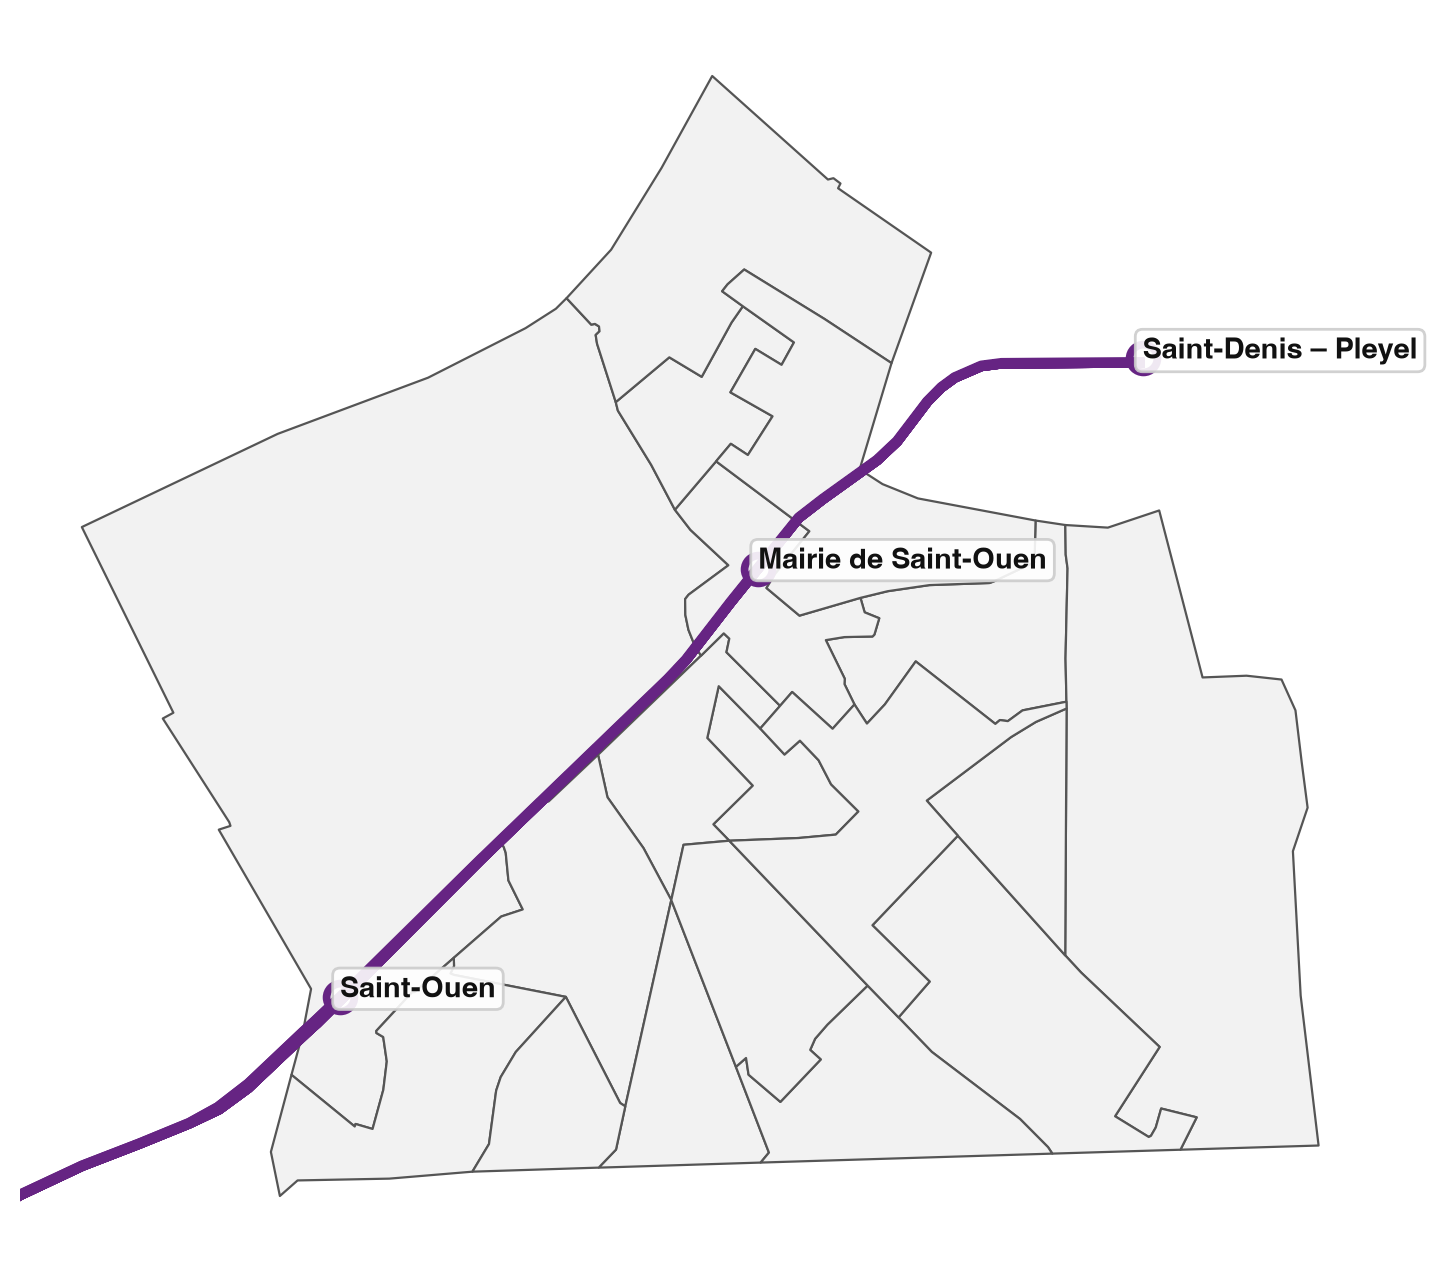

In [ ]:
# Visualisation de la zone d'étude et de la ligne 14
fig, ax = plt.subplots(figsize=(10, 8))

zone_etude.plot(
    ax=ax,
    color="#f2f2f2",
    edgecolor="#555555",
    linewidth=0.8,
)
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=4)
stations_st_ouen.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.8,
    markersize=100,
    zorder=3,
)

etiqueter_stations(ax, stations_st_ouen, fontsize=10.5)
cadrer_carte(ax, zone_etude)

plt.show()

In [ ]:
# 1. Répartition par nature de mutation (effectifs + pourcentages)
df_nature = pd.DataFrame(
    {
        "Effectif": df_logements["nature_mutation"].value_counts(dropna=False),
        "Proportion (%)": (
            df_logements["nature_mutation"].value_counts(
                normalize=True, dropna=False
            )
            * 100
        ).round(1),
    }
)

print("=== Répartition par nature de mutation ===")
print(df_nature)
print("\n" + "=" * 45 + "\n")

# 2. Répartition par type de local (effectifs + pourcentages)
df_type = pd.DataFrame(
    {
        "Effectif": df_logements["type_local"].value_counts(dropna=False),
        "Proportion (%)": (
            df_logements["type_local"].value_counts(
                normalize=True, dropna=False
            )
            * 100
        ).round(1),
    }
)

print("=== Répartition par type de local ===")
print(df_type)

=== Répartition par nature de mutation ===
                                    Effectif  Proportion (%)
nature_mutation                                             
Vente                                   3304            78.8
Vente en l'état futur d'achèvement       888            21.2


=== Répartition par type de local ===
             Effectif  Proportion (%)
type_local                           
Appartement      4007            95.6
Maison            185             4.4


On constate que sur la période de 2017 à 2025 près de 20% des actes notariés de ventes d'appartements et de maisons enregistrés à Saint-Ouen sont des ventes en l'état futur d'achèvement, i.e. des logements (appartements ou maisons) achetés sur plan, dont près de 95% sont des appartements.

On peut regarder une ville comparable qui a pas eu la 14 pour voir si c'est vrmt le métro qui a eu un effet et pas juste l'évolution naturelle du marché immobilier. Pour détrender on regarde ce qu'aurait été le marché à St Ouen avec un coef régional d'évolution du prix de l'immobilier, et comaprer à la réalité. 

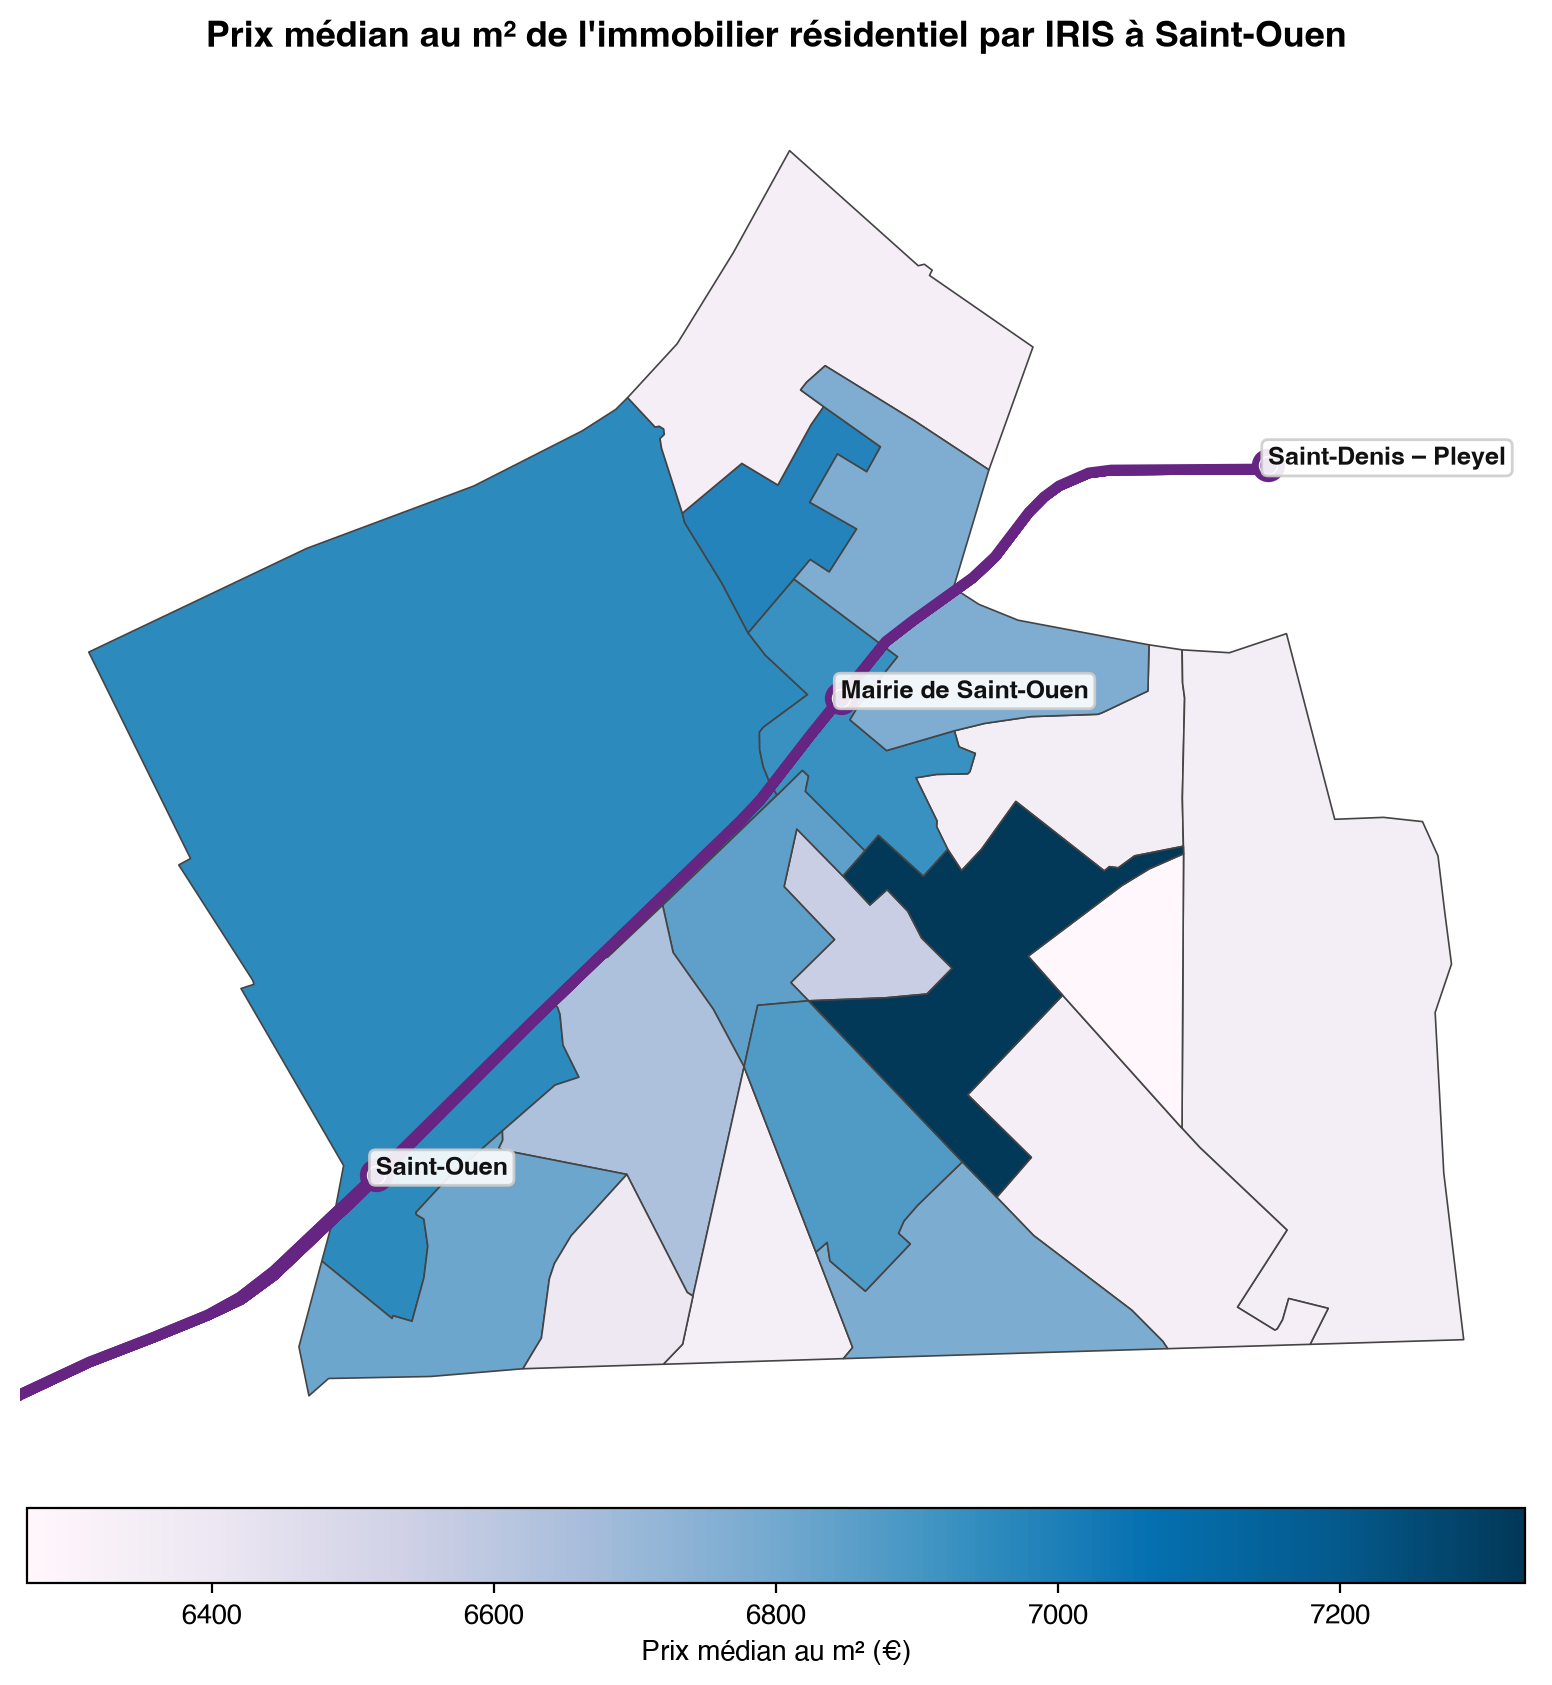

In [ ]:
# Carte choroplèthe : prix médian au m² par IRIS
fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_dvf.plot(
    column="prix_m2_median",
    cmap="PuBu",
    linewidth=0.6,
    edgecolor="#444444",
    legend=True,
    legend_kwds={
        "label": "Prix médian au m² (€)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.03,
    },
    missing_kwds={"color": "#e0e0e0", "label": "Ventes insuffisantes"},
    ax=ax,
    zorder=1,
)

# Superposition ligne 14 et stations
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=3)
stations_st_ouen.plot(
    ax=ax, color="white", edgecolor="#662483", linewidth=2.5,
    markersize=90, zorder=4,
)
stations_st_ouen.plot(ax=ax, color="#662483", markersize=25, zorder=5)

etiqueter_stations(ax, stations_st_ouen, fontsize=9)
cadrer_carte(ax, zone_etude)

ax.set_title(
    "Prix médian au m² de l'immobilier résidentiel par IRIS à Saint-Ouen",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()
plt.show()

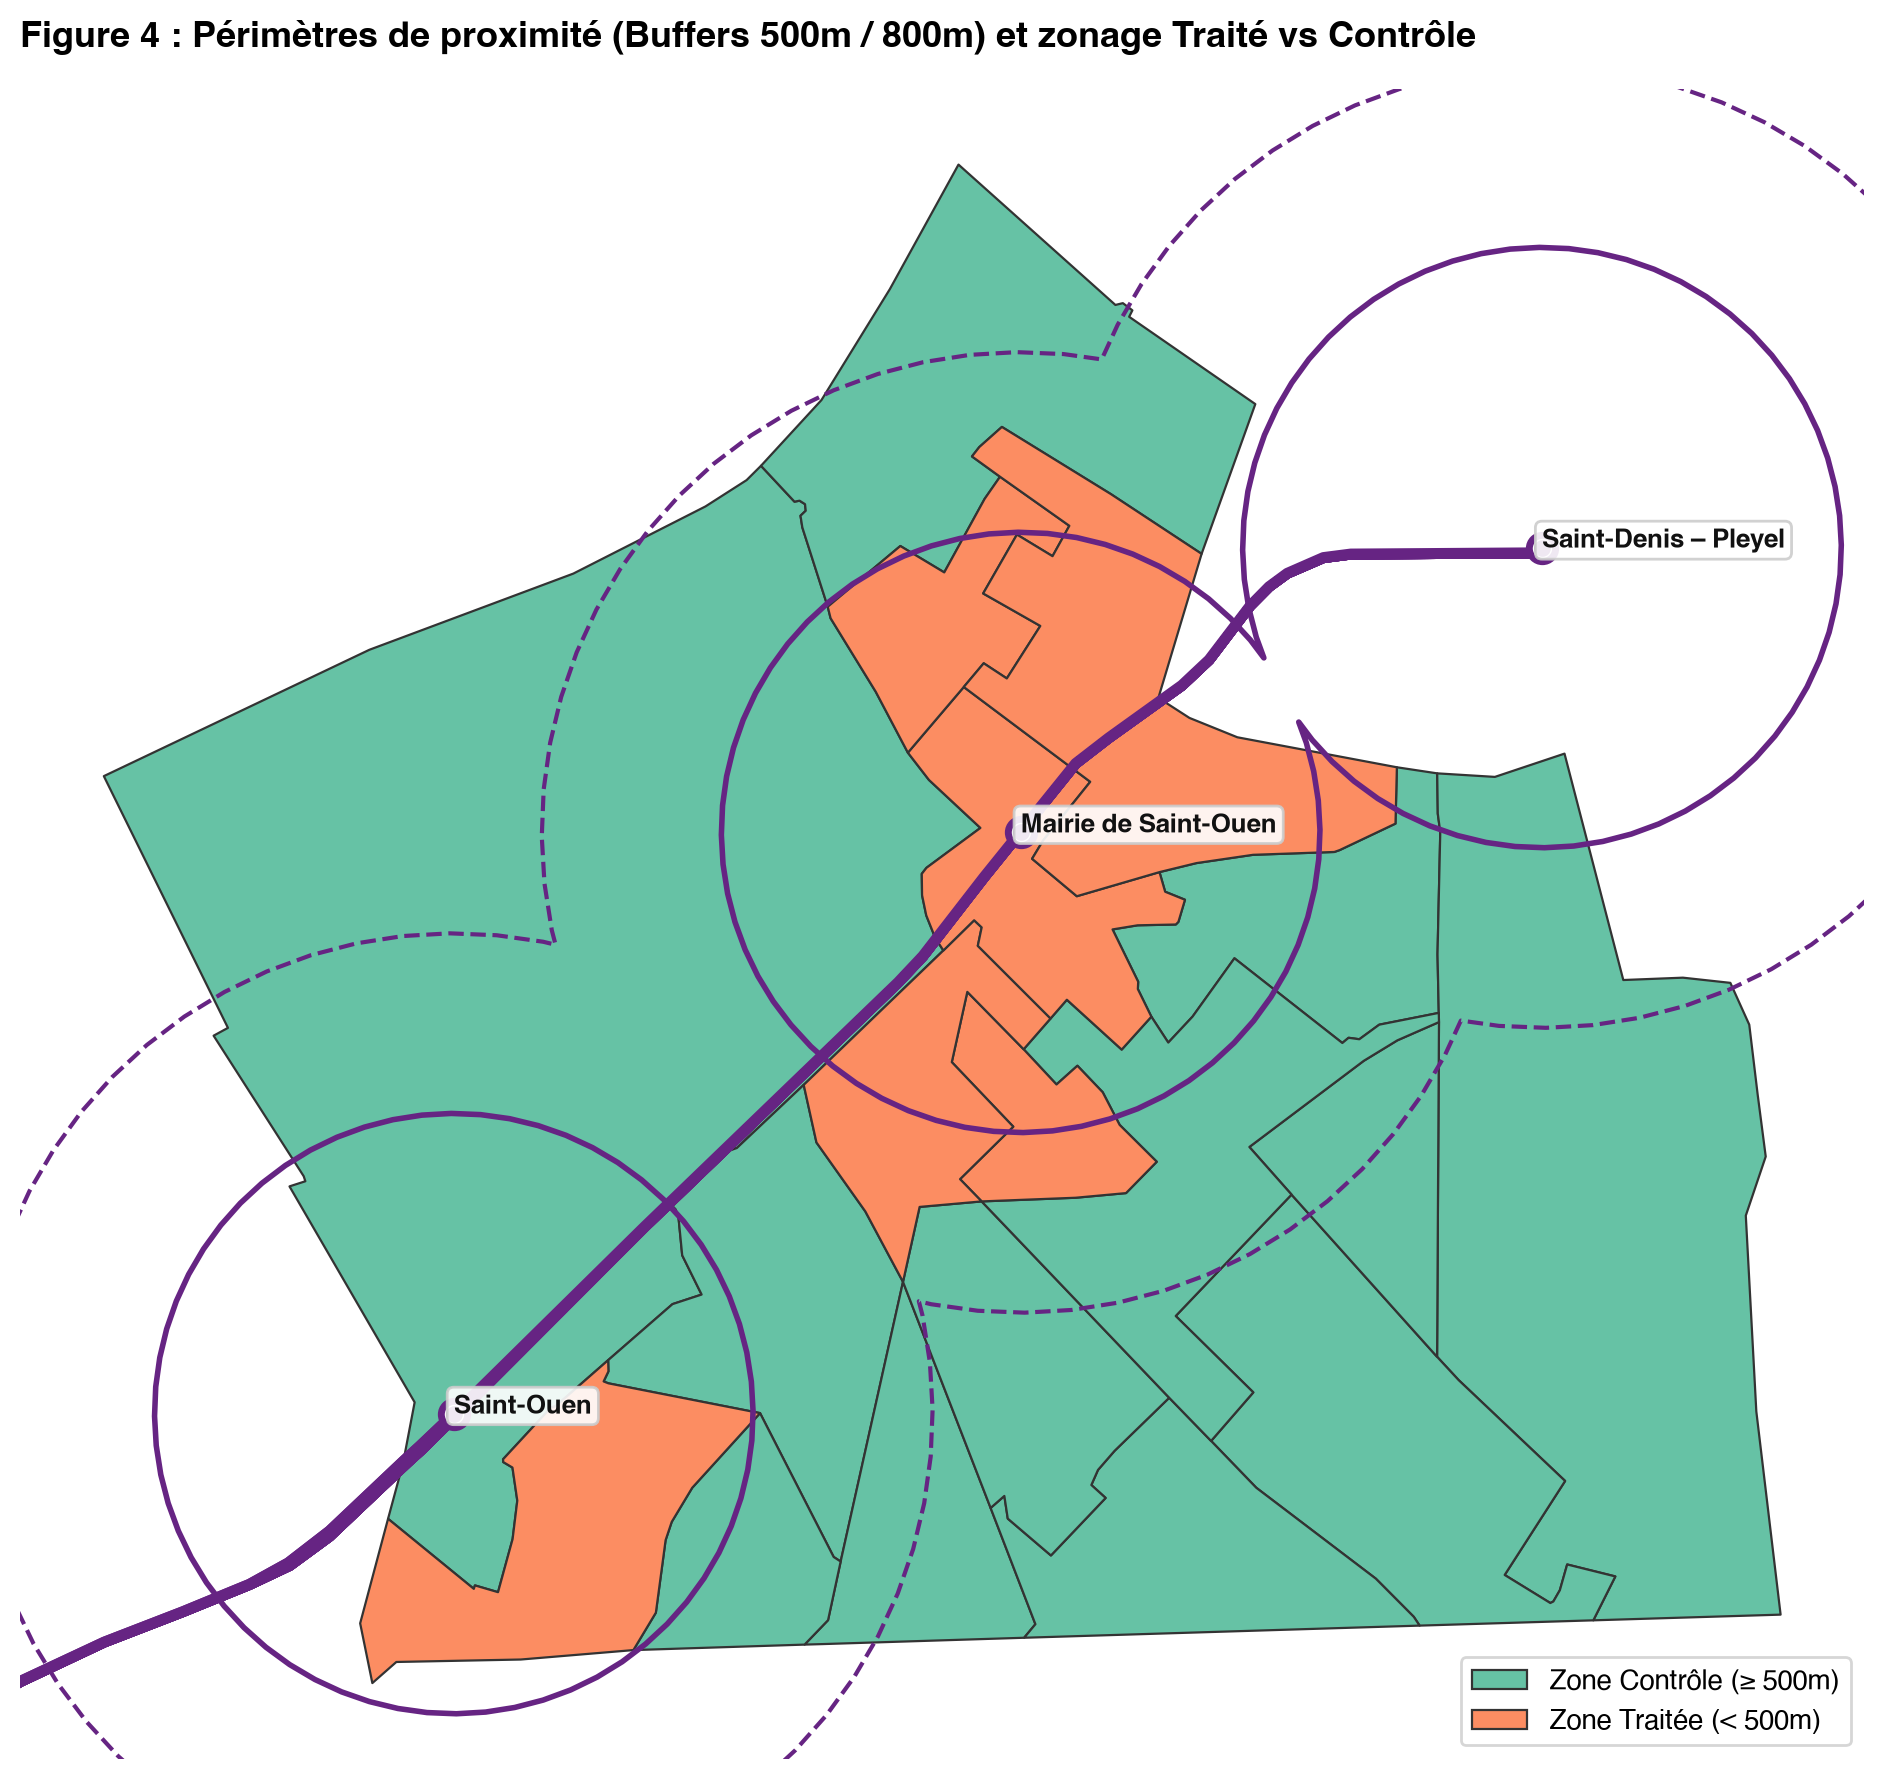

In [ ]:
#Méthode DiD pour analyser l'effet de l'arrivée de la ligne 14 (étape finale)

def analyser_evolution_prix_groupes(df_logements, zone_etude_analysis):
    """Rattache chaque vente à son IRIS (jointure spatiale) puis calcule
    l'évolution annuelle du prix médian au m² par groupe Traité / Contrôle."""
    zone = zone_etude_analysis[["code_iris", "groupe", "dist_station_m", "geometry"]].copy()
    zone["code_iris"] = zone["code_iris"].astype(str)

    ventes = (
        df_logements
        .drop(columns=["code_iris"], errors="ignore")   # évite le conflit left/right
        .dropna(subset=["longitude", "latitude"])
    )
    gdf_ventes = gpd.GeoDataFrame(
        ventes,
        geometry=gpd.points_from_xy(ventes["longitude"], ventes["latitude"]),
        crs="EPSG:4326",
    ).to_crs(zone.crs)

    df_analyse = gpd.sjoin(gdf_ventes, zone, how="inner", predicate="within")
    df_analyse = df_analyse.drop(columns="index_right")

    table_prix = df_analyse.groupby(["annee", "groupe"])["prix_m2"].median().unstack()
    return df_analyse, table_prix


zone_etude, ligne_14, stations_st_ouen = charger_carte_et_transports("93070")
zone_etude_analysis, gdf_buf_500, gdf_buf_800 = calculer_zones_tampons(
    zone_etude, stations_st_ouen, dist_traitee=500, dist_etendue=800
)

# Zonage Traité vs Contrôle
zone_etude_analysis, gdf_buf_500, gdf_buf_800 = calculer_zones_tampons(
    zone_etude, stations_st_ouen, dist_traitee=500, dist_etendue=800
)

# Figure 4 : Périmètres de proximité et zonage
fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_analysis.plot(
    column="groupe",
    categorical=True,
    cmap="Set2",
    linewidth=0.8,
    edgecolor="#333333",
    legend=True,
    legend_kwds={"loc": "lower right", "frameon": True},
    ax=ax,
    zorder=1,
)

# Cercles tampons
gdf_buf_800.plot(
    ax=ax, facecolor="none", edgecolor="#662483",
    linestyle="--", linewidth=1.5, zorder=2,
)
gdf_buf_500.plot(
    ax=ax, facecolor="none", edgecolor="#662483",
    linewidth=2.0, zorder=3,
)

# Ligne 14 et stations
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=4)
stations_st_ouen.plot(
    ax=ax, color="white", edgecolor="#662483", linewidth=2.5,
    markersize=90, zorder=5,
)
stations_st_ouen.plot(ax=ax, color="#662483", markersize=25, zorder=6)

etiqueter_stations(ax, stations_st_ouen, fontsize=9.5)
cadrer_carte(ax, zone_etude_analysis)

ax.set_title(
    "Figure 4 : Périmètres de proximité (Buffers 500m / 800m) et zonage Traité vs Contrôle",
    fontsize=13,
    fontweight="bold",
    pad=15,
    loc="left",
)

plt.tight_layout()
plt.show()

=== Prix médian au m² (€) par groupe et par année ===
groupe  Zone Contrôle (≥ 500m)  Zone Traitée (< 500m)
annee                                                
2018                    5292.0                 5366.0
2019                    5866.0                 6066.0
2020                    6314.0                 6386.0
2021                    6773.0                 6965.0
2022                    6970.0                 7019.0
2023                    6970.0                 7019.0
2024                    6360.0                 6385.0
2025                    6466.0                 6451.0


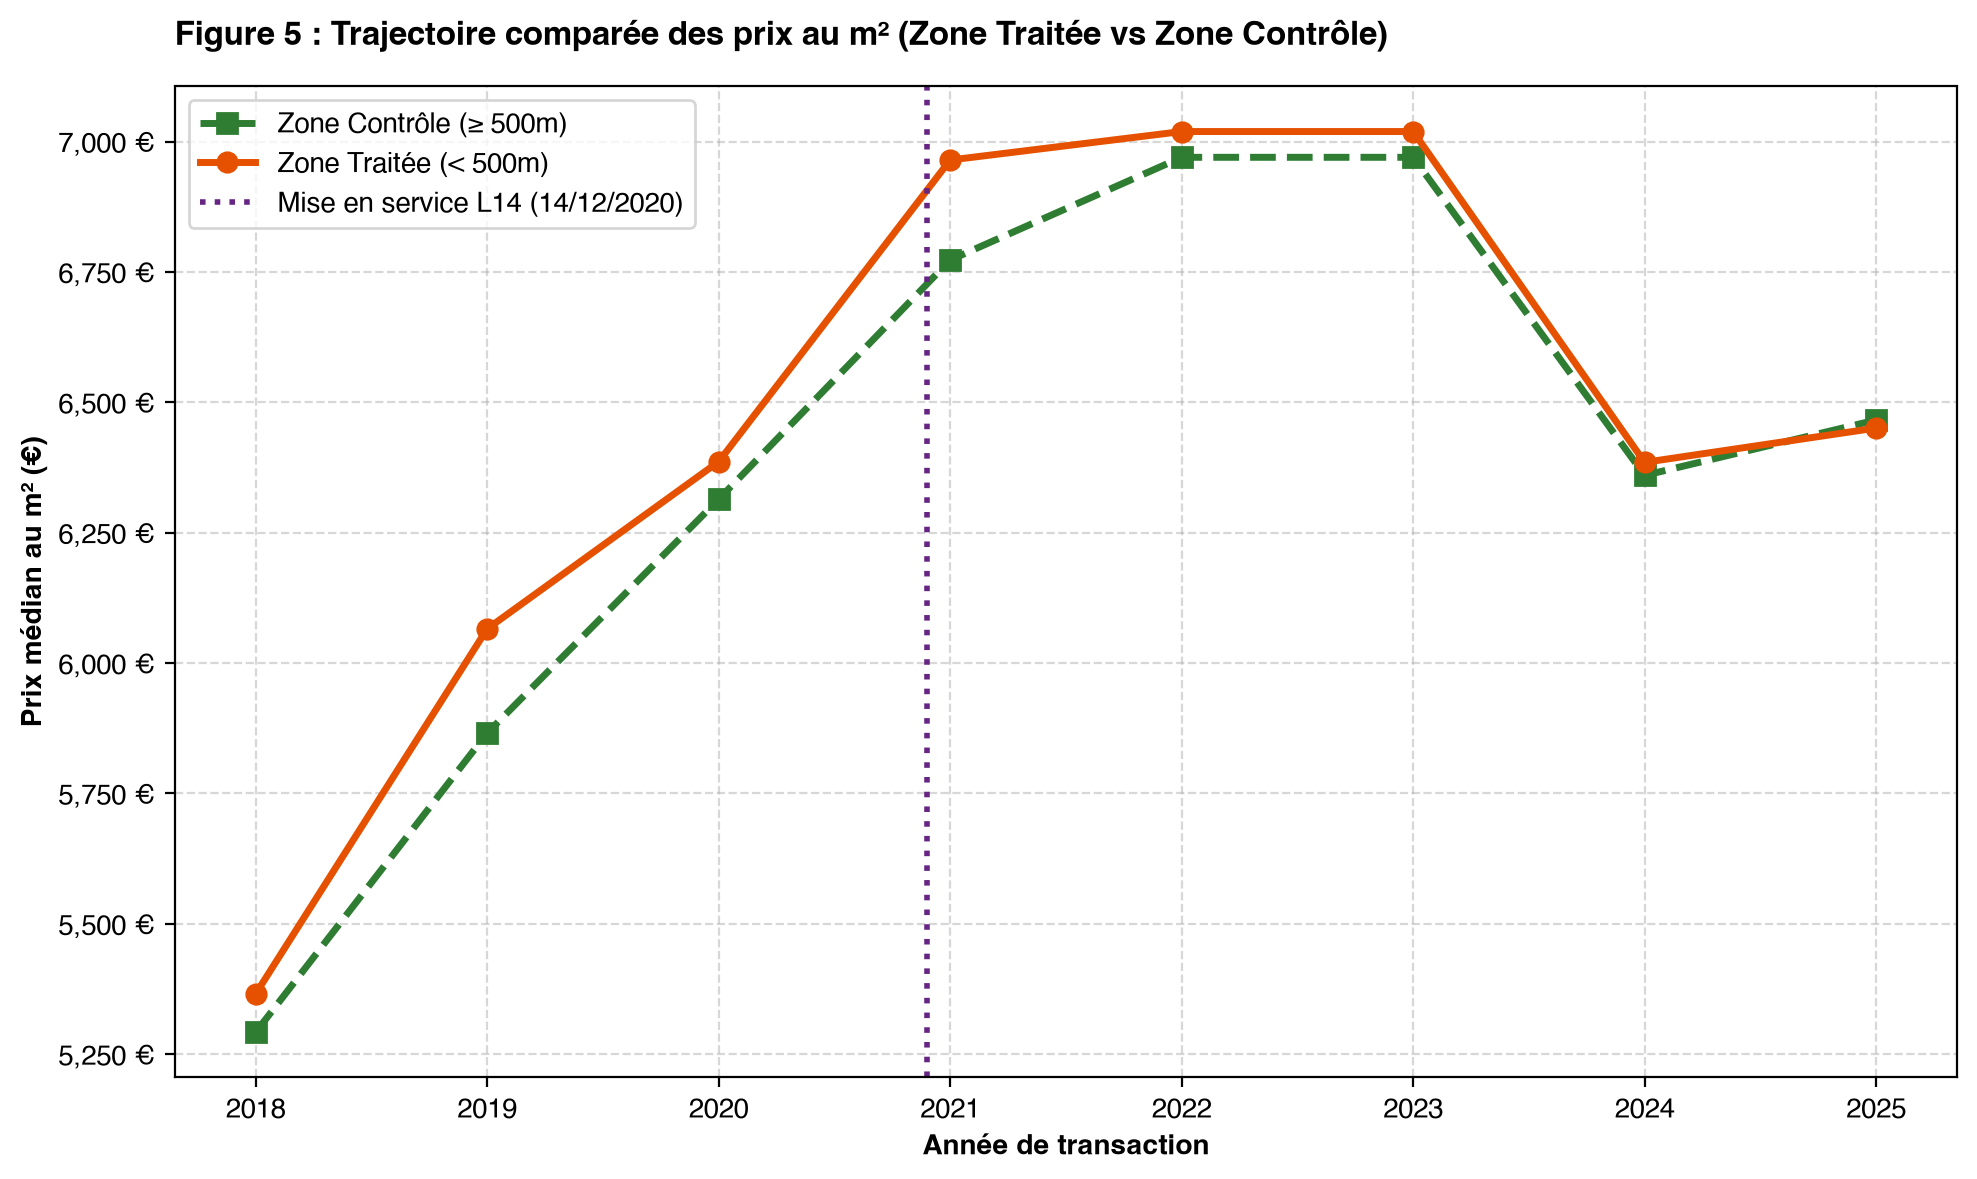

In [55]:
# 1. Calcul des prix médians par année et par zone
df_analyse, table_prix = analyser_evolution_prix_groupes(
    df_logements, zone_etude_analysis
)

# Affichage du tableau récapitulatif
print("=== Prix médian au m² (€) par groupe et par année ===")
print(table_prix.round(0))

# 2. Tracé des trajectoires temporelles
fig, ax = plt.subplots(figsize=(10, 6))

couleurs = {
    "Zone Traitée (< 500m)": "#e65100",
    "Zone Contrôle (≥ 500m)": "#2e7d32",
}
styles = {"Zone Traitée (< 500m)": "o-", "Zone Contrôle (≥ 500m)": "s--"}

for col in table_prix.columns:
    ax.plot(
        table_prix.index,
        table_prix[col],
        styles.get(col, "o-"),
        color=couleurs.get(col, "#333333"),
        linewidth=2.5,
        markersize=7,
        label=col,
    )

# Repère temporel : Inauguration Ligne 14 (Décembre 2020)
ax.axvline(
    x=2020.9,
    color="#662483",
    linestyle=":",
    linewidth=2,
    label="Mise en service L14 (14/12/2020)",
)

# Habillage et légendes
ax.set_title(
    "Figure 5 : Trajectoire comparée des prix au m² (Zone Traitée vs Zone Contrôle)",
    fontsize=12,
    fontweight="bold",
    pad=15,
    loc="left",
)
ax.set_xlabel("Année de transaction", fontsize=10, fontweight="bold")
ax.set_ylabel("Prix médian au m² (€)", fontsize=10, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")

# Formatage de l'axe des ordonnées en euros (€)
ax.yaxis.set_major_formatter("{x:,.0f} €")

plt.tight_layout()
plt.show()

In [ ]:
# Quel est le vrai nom de la colonne IRIS dans tes données ?
print([c for c in df_logements.columns if "iris" in c.lower()])

[]


In [ ]:
print(df_logements["annee"].value_counts().sort_index())

annee
2017     817
2018     710
2019     681
2020     266
2021     986
2022    1862
2024     591
2025     753
Name: count, dtype: int64


In [54]:
import pandas as pd
import glob

# Lister les fichiers .parquet disponibles
fichiers = glob.glob("*.parquet")
print(fichiers)

# Inspecter le premier fichier trouvé
if fichiers:
    df_test = pd.read_parquet(fichiers[0])
    print("\nDimensions :", df_test.shape)
    print("\nColonnes :")
    print(df_test.columns.tolist())

    # Chercher les colonnes utiles pour la localisation et l'IRIS
    print("\nColonnes liées à la géographie / IRIS :")
    print([c for c in df_test.columns
           if any(k in c.lower() for k in ("iris", "lat", "lon", "x", "y", "commune", "geom"))])

    # Aperçu des premières lignes
    display(df_test.head(3))

['dvf-2018.parquet', 'dvf-2019.parquet', 'dvf-2020.parquet']

Dimensions : (3335292, 40)

Colonnes :
['id_mutation', 'date_mutation', 'numero_disposition', 'nature_mutation', 'valeur_fonciere', 'adresse_numero', 'adresse_suffixe', 'adresse_nom_voie', 'adresse_code_voie', 'code_postal', 'code_commune', 'nom_commune', 'code_departement', 'ancien_code_commune', 'ancien_nom_commune', 'id_parcelle', 'ancien_id_parcelle', 'numero_volume', 'lot1_numero', 'lot1_surface_carrez', 'lot2_numero', 'lot2_surface_carrez', 'lot3_numero', 'lot3_surface_carrez', 'lot4_numero', 'lot4_surface_carrez', 'lot5_numero', 'lot5_surface_carrez', 'nombre_lots', 'code_type_local', 'type_local', 'surface_reelle_bati', 'nombre_pieces_principales', 'code_nature_culture', 'nature_culture', 'code_nature_culture_speciale', 'nature_culture_speciale', 'surface_terrain', 'longitude', 'latitude']

Colonnes liées à la géographie / IRIS :
['adresse_suffixe', 'code_commune', 'nom_commune', 'ancien_code_commune', 'ancien_nom_co

,id_mutation,date_mutation,numero_disposition,nature_mutation,valeur_fonciere,adresse_numero,adresse_suffixe,adresse_nom_voie,adresse_code_voie,code_postal,...,type_local,surface_reelle_bati,nombre_pieces_principales,code_nature_culture,nature_culture,code_nature_culture_speciale,nature_culture_speciale,surface_terrain,longitude,latitude
0,2018-1,2018-01-03,000001,Vente,109000.0,13.0,NaN,RUE GEN LOGEROT,1660,01000,...,Appartement,73.0,4.0,NaN,NaN,NaN,NaN,NaN,5.220440,46.200062
1,2018-1,2018-01-03,000001,Vente,109000.0,13.0,NaN,RUE GEN LOGEROT,1660,01000,...,Dépendance,NaN,0.0,NaN,NaN,NaN,NaN,NaN,5.220440,46.200062
2,2018-2,2018-01-04,000001,Vente,239300.0,4.0,NaN,RUE DE LA BARMETTE,0025,01250,...,Maison,163.0,4.0,S,sols,NaN,NaN,949.0,5.408041,46.255562


In [53]:
df_logements = charger_et_nettoyer_dvf("93070")

# 1. Toutes les années ont-elles des coordonnées ?
print(df_logements.groupby("annee").agg(
    nb_ventes=("prix_m2", "size"),
    nb_avec_lonlat=("longitude", lambda s: s.notna().sum()),
))

# 2. Le pivot couvre-t-il toute la période ?
df_analyse, table_prix = analyser_evolution_prix_groupes(df_logements, zone_etude_analysis)
print(table_prix.round(0))

⚠️ 2017 : aucun fichier trouvé
✔ dvf-2018.parquet : 2296 lignes pour 2018
✔ dvf-2019.parquet : 3140 lignes pour 2019
✔ dvf-2020.parquet : 2540 lignes pour 2020
✔ 93070.2021.csv : 3462 lignes pour 2021
✔ 93070.2022.csv : 3019 lignes pour 2022
✔ 93070.2023.csv : 3019 lignes pour 2023
✔ 93070.2024.csv : 2471 lignes pour 2024
✔ 93070.2025.csv : 2650 lignes pour 2025
       nb_ventes  nb_avec_lonlat
annee                           
2018         754             750
2019         861             857
2020         869             834
2021         986             969
2022         931             925
2023         931             925
2024         591             590
2025         753             750
groupe  Zone Contrôle (≥ 500m)  Zone Traitée (< 500m)
annee                                                
2018                    5292.0                 5366.0
2019                    5866.0                 6066.0
2020                    6314.0                 6386.0
2021                    6773.0     

In [51]:
print(sorted(glob.glob("*.parquet")))
print(sorted(glob.glob("*.csv")))
print(df_logements["annee"].value_counts().sort_index())

['dvf-2018.parquet', 'dvf-2019.parquet', 'dvf-2020.parquet']
['93070.2021.csv', '93070.2022.csv', '93070.2023.csv', '93070.2024.csv', '93070.2025.csv', 'dvf.csv']
annee
2018    754
2019    861
2020    869
Name: count, dtype: int64
